# Feature Importance -- Autoencoder-Encoded Branch, Combined Ranking, and Tab Diagnosis

This notebook follows on from `09_feature_importance_analysis.ipynb` and covers the three things your supervisor asked for that notebook didn't:

1. **Permutation importance on the autoencoder-encoded models.** `09_feature_importance_analysis.ipynb` only ran this for the Original (engineered-feature) branch. Here it's run the same way -- same method, same 8 repeats, same seed -- but on Random Forest and XGBoost trained on the 8 latent `encoded_0`..`encoded_7` dimensions instead.
2. **A full feature list ranked across models, and a look at why the "Feature importance comparison" tab looked broken.**
3. **Figures showing where Random Forest and XGBoost actually disagree**, not just the summary Spearman number.

Same rules as before: nothing here is retrained, only already-fitted models and their real, already-split test sets are used, and there's no SHAP anywhere.

Run this from `notebooks/`, after `09_feature_importance_analysis.ipynb` has already been run once (this notebook reads some of its saved outputs).


In [1]:
import sys
from pathlib import Path


def find_project_root(start, marker):
    start = start.resolve()

    for p in [start, *start.parents]:
        if (p / marker).exists():
            return p

    raise FileNotFoundError(
        f"Can't find a '{marker}' folder anywhere above {start}. "
        "Move this notebook into AI_Crypto_Forecasting/notebooks/ and run it from there."
    )


PROJECT_ROOT = find_project_root(Path.cwd(), "src")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import joblib
import matplotlib.pyplot as plt
from IPython.display import Image
import numpy as np
import pandas as pd


from src import config
from src.models.feature_naming import _horizon_suffix, DISPLAY_NAMES
from src.feature_importance.permutation import calculate_permutation_importance, N_REPEATS, SEED
from src.feature_importance.grouping import build_feature_dictionary
from src.feature_importance.aggregate import (
    compare_model_rankings,
    compute_rank_agreement_summary,
    calculate_feature_group_importance,
    create_importance_summary,
)


ORIGINAL_DIR = PROJECT_ROOT / "results" / "feature_importance"
ORIGINAL_RAW_DIR = ORIGINAL_DIR / "raw"
ORIGINAL_PROCESSED_DIR = ORIGINAL_DIR / "processed"

AE_DATA_DIR = PROJECT_ROOT / "results" / "autoencoder" / "encoded_features"
FITTED_MODELS_DIR = PROJECT_ROOT / "results" / "modeling" / "fitted_models"

RESULTS_DIR = PROJECT_ROOT / "results" / "feature_importance_autoencoder"
FIGURES_DIR = RESULTS_DIR / "figures"
RAW_DIR = RESULTS_DIR / "raw"
PROCESSED_DIR = RESULTS_DIR / "processed"

for d in (FIGURES_DIR, RAW_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

REPRESENTATION = "Autoencoder-Encoded"

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 10

print(f"Project root: {PROJECT_ROOT}")
print(f"Repeats per permutation: {N_REPEATS}, seed: {SEED}")
print(f"New results directory (nothing in {ORIGINAL_DIR} is touched): {RESULTS_DIR}")

Project root: /Users/mas364/Desktop/AI_Crypto_Forecasting
Repeats per permutation: 8, seed: 42
New results directory (nothing in /Users/mas364/Desktop/AI_Crypto_Forecasting/results/feature_importance is touched): /Users/mas364/Desktop/AI_Crypto_Forecasting/results/feature_importance_autoencoder


## 1. Setting up the autoencoder-encoded experiment grid

Same grid as the Original branch: 2 assets x 3 horizons x 4 feature configurations (Market Only, Market + Google Trends, Market + Fear & Greed Index, Market + Google Trends + Fear & Greed Index) x 2 models = 48 experiments.

The project's existing loader ignores the representation you ask it for and always loads the Original branch, so this notebook has its own loader below for the autoencoder-encoded files. It reuses the same permutation-importance function as before -- it only ever calls `.predict()`, so it doesn't care what the model's inputs actually represent.

File paths and naming below are copied straight from `src/pipeline.py`'s own encoded-branch logic, not guessed.


In [2]:
from itertools import product

# feature_set_key -> real feature configuration name (src.models.feature_naming.DISPLAY_NAMES)
#   primary   -> Market Only
#   candidate -> Market + Google Trends
#   ablation  -> Market + Fear & Greed Index
#   combined  -> Market + Google Trends + Fear & Greed Index
# The raw keys below have to stay as-is -- they're the real file-naming
# convention on disk (e.g. bitcoin_primary_encoded_test.csv), not just labels.
ASSETS = ["Bitcoin", "Ethereum"]
HORIZONS = [1, 7, 14]
FEATURE_SET_KEYS = ["primary", "candidate", "ablation", "combined"]
MODELS = ["Random Forest", "XGBoost"]


def load_encoded_model_and_data(horizon, asset, feature_set_key, model_name):
    price_col = config.ASSET_VARIABLES[asset]["price"]
    suffix = _horizon_suffix(horizon)
    prefix = f"{asset.lower()}_{feature_set_key}{suffix}"
    model_slug = model_name.lower().replace(" ", "_")

    test_path = AE_DATA_DIR / f"{prefix}_encoded_test.csv"
    if not test_path.exists():
        raise FileNotFoundError(f"Encoded test set not found: {test_path}")

    model_path = FITTED_MODELS_DIR / f"{prefix}_{model_slug}_encoded.joblib"
    if not model_path.exists():
        raise FileNotFoundError(f"Encoded model not found: {model_path}")

    df = pd.read_csv(test_path)
    encoded_cols = [c for c in df.columns if c.startswith("encoded_")]
    target_col = f"{price_col}_log_return_target_t_plus_{horizon}"
    if target_col not in df.columns:
        raise FileNotFoundError(f"Expected target column '{target_col}' not found in {test_path}")

    return {"model": joblib.load(model_path), "X_test": df[encoded_cols], "y_test": df[target_col]}


def run_encoded_experiment(horizon, asset, feature_set_key, model_name):
    loaded = load_encoded_model_and_data(horizon, asset, feature_set_key, model_name)
    pfi = calculate_permutation_importance(loaded["model"], loaded["X_test"], loaded["y_test"])
    pfi["asset"] = asset
    pfi["horizon"] = horizon
    pfi["feature_set_key"] = feature_set_key
    pfi["model_name"] = model_name
    pfi["representation"] = REPRESENTATION
    return pfi


specs = [
    {"horizon": h, "asset": a, "feature_set_key": f, "model_name": m}
    for h, a, f, m in product(HORIZONS, ASSETS, FEATURE_SET_KEYS, MODELS)
]
print(f"{len(specs)} Autoencoder-Encoded experiments queued.")


48 Autoencoder-Encoded experiments queued.


## 2. Running permutation importance (autoencoder-encoded)

Same as before, just pointed at the loader above. Nothing gets retrained -- this only calls `.predict()` on shuffled copies of the real test set.


In [3]:
all_results_ae = []
n_ok, n_skip, n_fail = 0, 0, 0

for i, spec in enumerate(specs, 1):
    fset_name = DISPLAY_NAMES[spec["feature_set_key"]]
    label = f"{spec['asset']} h={spec['horizon']}d {fset_name:45s} {spec['model_name']}"
    try:
        pfi = run_encoded_experiment(**spec)
        all_results_ae.append(pfi)
        n_ok += 1
        print(f"[{i:2d}/{len(specs)}] OK:   {label} -- {len(pfi)} features")
    except FileNotFoundError as e:
        n_skip += 1
        print(f"[{i:2d}/{len(specs)}] SKIP (no saved model/data): {label} -- {e}")
    except Exception as e:
        n_fail += 1
        print(f"[{i:2d}/{len(specs)}] FAILED: {label} -- {type(e).__name__}: {e}")

print(f"\nDone: {n_ok} OK, {n_skip} skipped, {n_fail} failed.")

if not all_results_ae:
    raise RuntimeError(
        "No Autoencoder-Encoded permutation-importance results were produced. "
        "Check that results/autoencoder/encoded_features/ and the *_encoded.joblib "
        "files in results/modeling/fitted_models/ exist."
    )

long_df_ae = pd.concat(all_results_ae, ignore_index=True)
long_df_ae.to_csv(RAW_DIR / "permutation_importance_autoencoder_long.csv", index=False)
print(f"Saved: {len(long_df_ae)} rows -> {RAW_DIR / 'permutation_importance_autoencoder_long.csv'}")


[ 1/48] OK:   Bitcoin h=1d Market Only                                   Random Forest -- 8 features
[ 2/48] OK:   Bitcoin h=1d Market Only                                   XGBoost -- 8 features
[ 3/48] OK:   Bitcoin h=1d Market + Google Trends                        Random Forest -- 8 features
[ 4/48] OK:   Bitcoin h=1d Market + Google Trends                        XGBoost -- 8 features
[ 5/48] OK:   Bitcoin h=1d Market + Fear & Greed Index                   Random Forest -- 8 features
[ 6/48] OK:   Bitcoin h=1d Market + Fear & Greed Index                   XGBoost -- 8 features
[ 7/48] OK:   Bitcoin h=1d Market + Google Trends + Fear & Greed Index   Random Forest -- 8 features
[ 8/48] OK:   Bitcoin h=1d Market + Google Trends + Fear & Greed Index   XGBoost -- 8 features
[ 9/48] OK:   Ethereum h=1d Market Only                                   Random Forest -- 8 features
[10/48] OK:   Ethereum h=1d Market Only                                   XGBoost -- 8 features
[11/48] OK:   Ethe

## 3. Full feature list (Original + autoencoder-encoded)

This combines the Original-branch feature dictionary from `09_feature_importance_analysis.ipynb` with the 8 autoencoder latent dimensions, so there's one complete list of everything considered.

The 8 `encoded_0`..`encoded_7` dimensions don't correspond to any single real-world variable -- they're a learned, compressed mix -- so they're labelled "Other (Autoencoder Latent Dimension)" rather than forced into one of the engineered-feature groups.


In [4]:
original_feature_dict_path = ORIGINAL_PROCESSED_DIR / "feature_dictionary.csv"
if not original_feature_dict_path.exists():
    raise FileNotFoundError(
        f"{original_feature_dict_path} not found -- run 09_feature_importance_analysis.ipynb first."
    )

original_dict = pd.read_csv(original_feature_dict_path)
original_dict.insert(0, "representation", "Original")

encoded_dims = [f"encoded_{i}" for i in range(8)]
encoded_dict = pd.DataFrame([
    {
        "representation": "Autoencoder-Encoded", "feature": f,
        "feature_group": "Other (Autoencoder Latent Dimension)",
        "source": "Autoencoder (learned, compressed representation)",
        "engineering_method": "8-dimensional autoencoder bottleneck -- no single real-world source variable",
    }
    for f in encoded_dims
])

full_feature_dict = pd.concat([original_dict, encoded_dict], ignore_index=True)
full_feature_dict.to_csv(PROCESSED_DIR / "full_feature_dictionary.csv", index=False)

print(f"{len(full_feature_dict)} total features considered "
      f"({len(original_dict)} Original engineered + {len(encoded_dict)} Autoencoder-Encoded).\n")
display(full_feature_dict.groupby(["representation", "feature_group"]).size()
        .sort_values(ascending=False).reset_index(name="count"))

54 total features considered (46 Original engineered + 8 Autoencoder-Encoded).



,representation,feature_group,count
0,Original,Price & Return,16
1,Original,Trading Volume,14
2,Autoencoder-Encoded,Other (Autoencoder Latent Dimension),8
3,Original,Google Trends,8
4,Original,Fear & Greed / Sentiment,6
5,Original,Volatility,2


## 4. Random Forest vs XGBoost agreement -- autoencoder-encoded branch

Same rank-agreement analysis as before (Section 11 of `09_feature_importance_analysis.ipynb`), just run on the autoencoder-encoded results.


In [5]:
cross_model_ae = compare_model_rankings(long_df_ae)
cross_model_ae.to_csv(PROCESSED_DIR / "cross_model_comparison_autoencoder.csv", index=False)

rank_agreement_ae = compute_rank_agreement_summary(cross_model_ae)
rank_agreement_ae.to_csv(PROCESSED_DIR / "rank_agreement_summary_autoencoder.csv", index=False)

print(f"Mean Spearman rho across Autoencoder-Encoded configurations: {rank_agreement_ae['spearman_rho'].mean():.3f}")
print(f"Mean top-5 overlap: {rank_agreement_ae['top_5_overlap'].mean():.2f} / 5")
print(f"Mean top-10 overlap: {rank_agreement_ae['top_10_overlap'].mean():.2f} / 10")

display_df = rank_agreement_ae.sort_values("spearman_rho").reset_index(drop=True).copy()
display_df["feature_set_key"] = display_df["feature_set_key"].map(DISPLAY_NAMES)
display_df = display_df.rename(columns={"feature_set_key": "feature_configuration"})
display(display_df)


Mean Spearman rho across Autoencoder-Encoded configurations: 0.604
Mean top-5 overlap: 3.96 / 5
Mean top-10 overlap: 8.00 / 10


,asset,horizon,feature_configuration,representation,n_features_compared,spearman_rho,spearman_pvalue,top_5_overlap,top_10_overlap
0,Bitcoin,7,Market + Fear & Greed Index,Autoencoder-Encoded,8,-0.071429,0.866526,2,8
1,Ethereum,7,Market + Google Trends + Fear & Greed Index,Autoencoder-Encoded,8,0.000000,1.000000,3,8
2,Ethereum,1,Market + Fear & Greed Index,Autoencoder-Encoded,8,0.023810,0.955374,3,8
3,Bitcoin,7,Market + Google Trends,Autoencoder-Encoded,8,0.073193,0.863253,3,8
4,Bitcoin,1,Market Only,Autoencoder-Encoded,8,0.285714,0.492726,3,8
5,Ethereum,1,Market Only,Autoencoder-Encoded,8,0.285714,0.492726,3,8
6,Bitcoin,1,Market + Google Trends + Fear & Greed Index,Autoencoder-Encoded,8,0.545545,0.161938,3,8
7,Ethereum,14,Market Only,Autoencoder-Encoded,8,0.558081,0.150568,4,8
8,Ethereum,14,Market + Google Trends,Autoencoder-Encoded,8,0.561143,0.147860,4,8
9,Ethereum,1,Market + Google Trends,Autoencoder-Encoded,8,0.598813,0.116754,4,8


Compare the mean Spearman rho above to the Original branch's 0.247 (Section 11 of `09_feature_importance_analysis.ipynb`) -- don't assume in advance which one agrees more, just read the number once you've run the cell. There are also only 8 latent dimensions here versus 14-25 engineered features in the Original branch, so top-N overlap isn't directly comparable between the two -- Spearman rho is the fairer comparison.


## 5. One combined ranking table

Original + autoencoder-encoded importance results in a single long table, for anyone who wants to filter across the whole project rather than looking at the two branches separately.


In [6]:
original_long_path = ORIGINAL_RAW_DIR / "permutation_importance_long.csv"
if not original_long_path.exists():
    raise FileNotFoundError(f"{original_long_path} not found -- run 09_feature_importance_analysis.ipynb first.")

long_df_original = pd.read_csv(original_long_path)

combined_long = pd.concat([long_df_original, long_df_ae], ignore_index=True)
combined_long_path = PROCESSED_DIR / "combined_importance_ranking.csv"
combined_long.sort_values(
    ["representation", "asset", "horizon", "feature_set_key", "model_name", "rank"]
).to_csv(combined_long_path, index=False)

print(f"Saved combined importance ranking: {len(combined_long)} rows "
      f"(representations: {sorted(combined_long['representation'].unique())}) -> {combined_long_path}\n")

top_overall = combined_long.sort_values("mean_importance", ascending=False).head(10).copy()
top_overall["feature_set_key"] = top_overall["feature_set_key"].map(DISPLAY_NAMES)
top_overall = top_overall.rename(columns={"feature_set_key": "feature_configuration"})
display(top_overall[["representation", "asset", "horizon", "feature_configuration", "model_name",
                      "feature", "mean_importance", "rank"]].reset_index(drop=True))


Saved combined importance ranking: 1328 rows (representations: ['Autoencoder-Encoded', 'Original']) -> /Users/mas364/Desktop/AI_Crypto_Forecasting/results/feature_importance_autoencoder/processed/combined_importance_ranking.csv



,representation,asset,horizon,feature_configuration,model_name,feature,mean_importance,rank
0,Original,Bitcoin,14,Market + Fear & Greed Index,XGBoost,Bitcoin_Price_log_return_rolling_std_30,0.002045,1
1,Autoencoder-Encoded,Ethereum,14,Market + Fear & Greed Index,XGBoost,encoded_6,0.001913,1
2,Original,Bitcoin,14,Market + Fear & Greed Index,XGBoost,Bitcoin_Price_log_return_rolling_mean_30,0.001496,2
3,Autoencoder-Encoded,Ethereum,14,Market + Fear & Greed Index,Random Forest,encoded_6,0.001070,1
4,Original,Ethereum,14,Market Only,XGBoost,Ethereum_Price_log_return_rolling_std_30,0.000995,1
5,Original,Bitcoin,7,Market + Google Trends + Fear & Greed Index,XGBoost,Bitcoin_Price_log_return_rolling_mean_30,0.000778,1
6,Original,Ethereum,14,Market + Google Trends + Fear & Greed Index,XGBoost,Ethereum_Volume_rolling_std_30,0.000725,1
7,Autoencoder-Encoded,Ethereum,14,Market + Google Trends + Fear & Greed Index,XGBoost,encoded_1,0.000653,1
8,Original,Bitcoin,14,Market + Google Trends,XGBoost,Bitcoin_Price_log_return_rolling_std_30,0.000634,1
9,Autoencoder-Encoded,Ethereum,14,Market + Google Trends + Fear & Greed Index,XGBoost,encoded_6,0.000626,2


## 6. Why the "Feature importance comparison" tab looked broken

Checked directly against the real code and files, not guessed:

- The API endpoints for this tab just read the CSVs in `results/feature_importance/processed/` and return them -- no bug there.
- Every column the Streamlit page expects is actually in those CSVs, with the right types.
- Running the page's own loading/pivoting logic by hand works fine, no errors.

**So there's no code or data bug locally -- it works fine against the real files.**

Most likely it's a deployment issue on Cloud Run, not a code issue:

1. **Wrong `CRYPTO_API_URL` on the deployed frontend.** The frontend reads the backend's URL from this environment variable. `docker-compose.yml` sets it correctly for local use (`http://api:8080`), but that hostname doesn't exist on Cloud Run. If it's wrong there, every page that talks to the API breaks, not just this tab. **Fix:** point the frontend's `CRYPTO_API_URL` at the backend's real Cloud Run URL and redeploy.
2. **A stale backend image.** The Dockerfile does copy the feature-importance CSVs into the image, but only as of whenever it was last built. If the live backend was built before these files existed, it won't have them. **Fix:** rebuild and redeploy the backend.

Open the tab and read the actual error -- "Can't reach the API" points to #1, "not found -- run ... first" points to #2.

Showing the autoencoder-encoded results in that same tab is a separate, real code change (new API endpoints + new Streamlit sections) that isn't made here, since this notebook isn't meant to edit the deployed app directly.


## 7. Figures -- where do RF and XGBoost actually disagree?

`09_feature_importance_analysis.ipynb` found a mean Spearman rank correlation of **0.247** between Random Forest and XGBoost across the 24 Original-branch configurations -- real, but not strong agreement. The figures below show why: a heatmap of every configuration's agreement, and a closer look at the single worst-agreeing one.


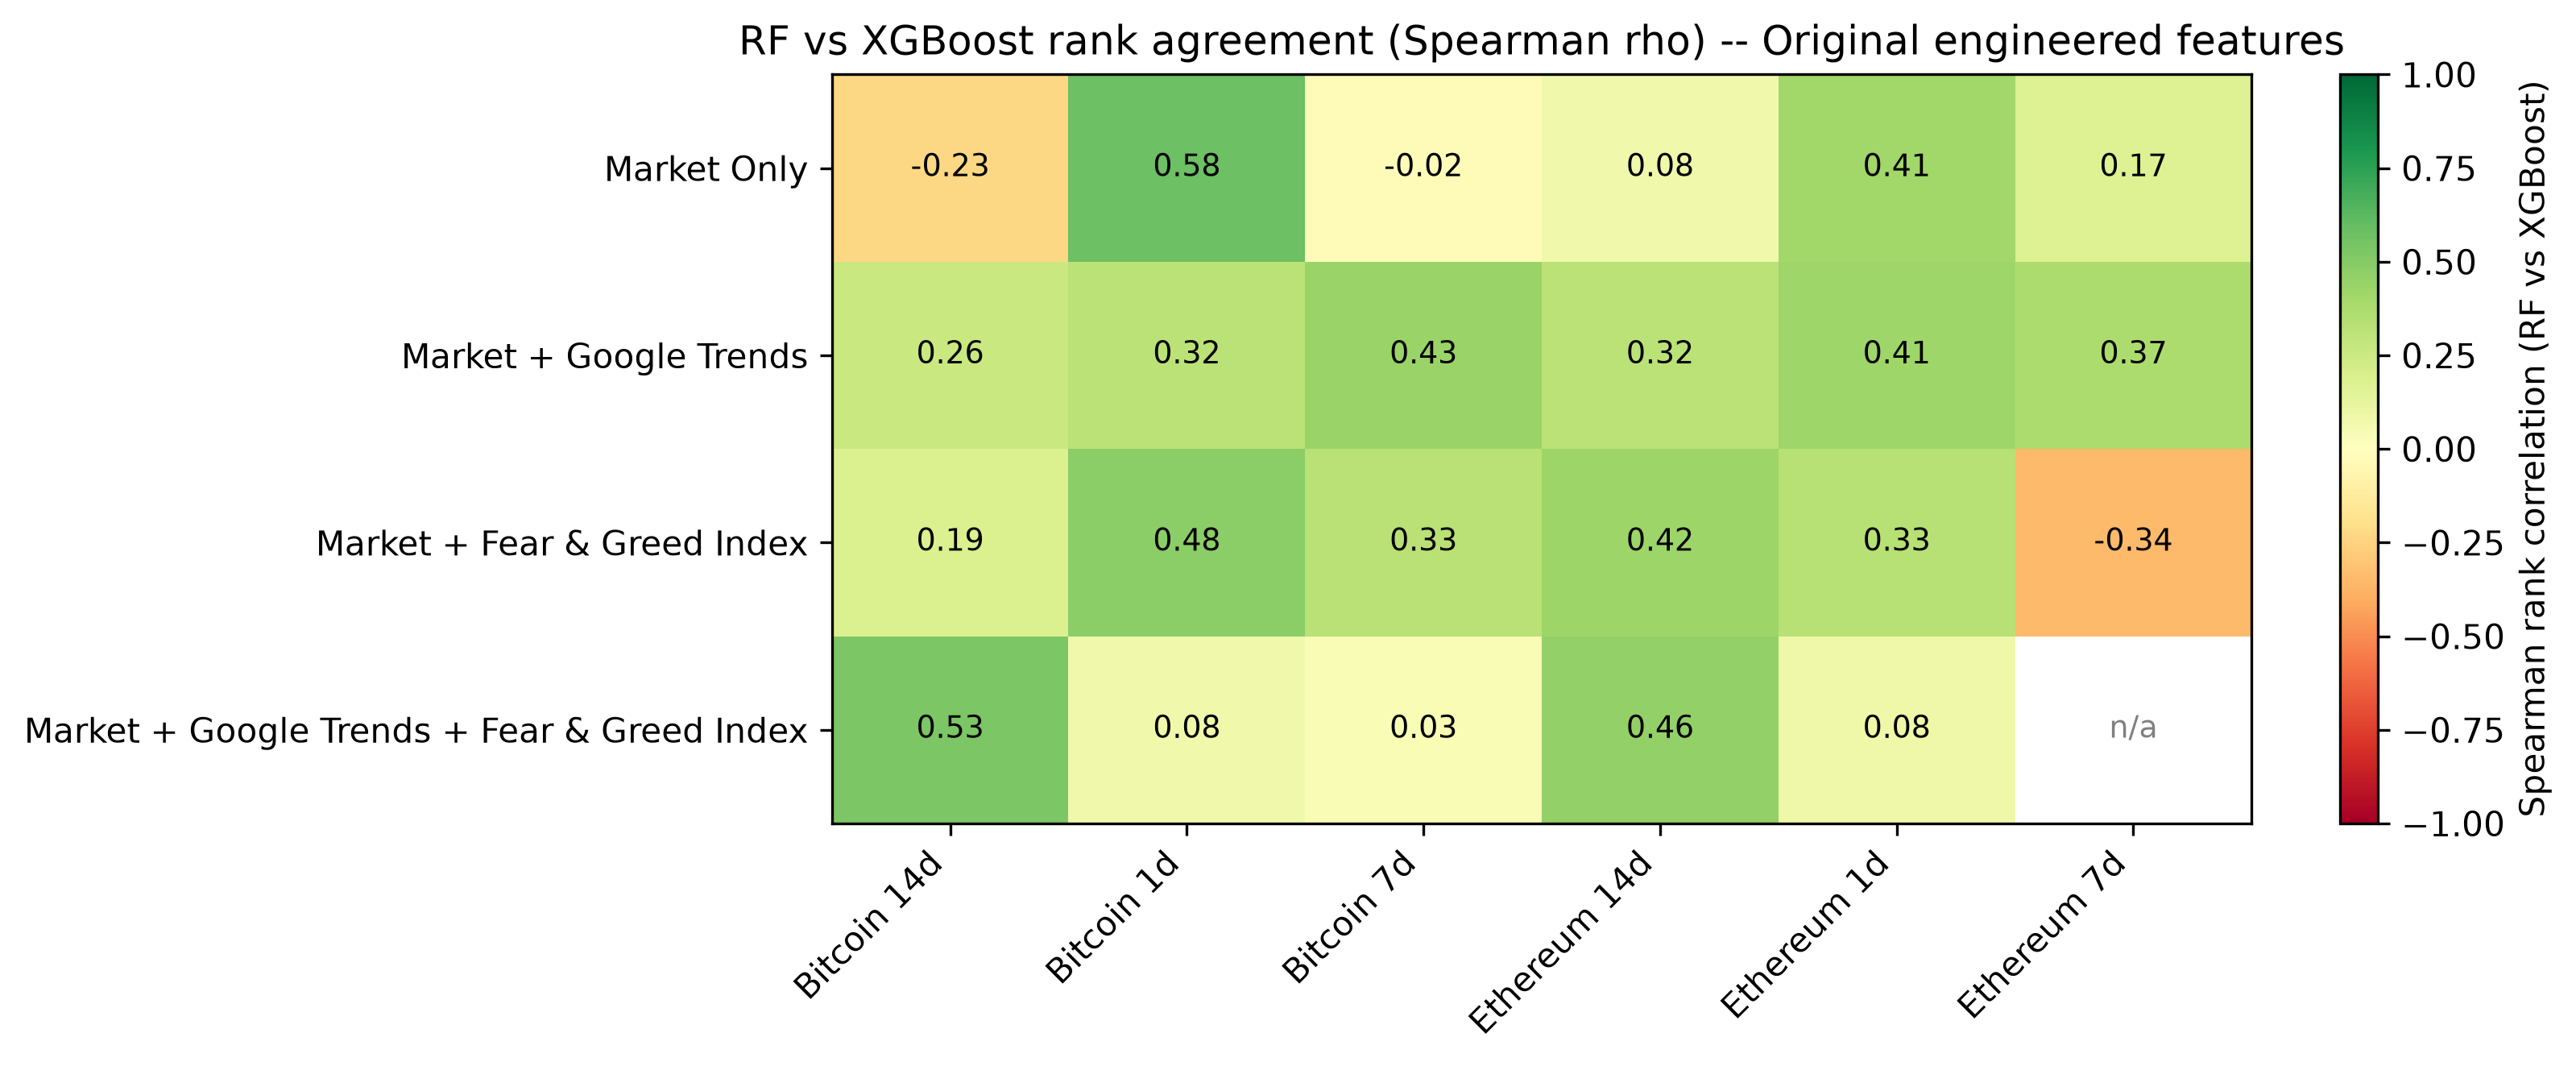

Saved: rank_agreement_heatmap_original.png


In [7]:
RF_COL, XGB_COL = "mean_importance_Random Forest", "mean_importance_XGBoost"
RF_RANK_COL, XGB_RANK_COL = "rank_Random Forest", "rank_XGBoost"


def build_heatmap_pivot(agreement_df):
    df = agreement_df.copy()
    df["feature_set_display"] = df["feature_set_key"].map(DISPLAY_NAMES)
    df["config_label"] = df["asset"] + " " + df["horizon"].astype(str) + "d"
    pivot = df.pivot(index="feature_set_display", columns="config_label", values="spearman_rho")
    order = [DISPLAY_NAMES[k] for k in ["primary", "candidate", "ablation", "combined"]]
    return pivot.reindex(order)


def plot_heatmap(pivot, title, out_path):
    fig, ax = plt.subplots(figsize=(11, 4.5))
    data = pivot.values.astype(float)
    im = ax.imshow(data, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data[i, j]
            ax.text(j, i, f"{val:.2f}" if not np.isnan(val) else "n/a",
                    ha="center", va="center", color="black" if not np.isnan(val) else "gray", fontsize=9)
    fig.colorbar(im, ax=ax, label="Spearman rank correlation (RF vs XGBoost)")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(out_path)))
    print(f"Saved: {out_path.name}")


original_agreement = pd.read_csv(ORIGINAL_PROCESSED_DIR / "rank_agreement_summary.csv")
original_cross_model = pd.read_csv(ORIGINAL_PROCESSED_DIR / "cross_model_comparison.csv")

pivot_original = build_heatmap_pivot(original_agreement)
plot_heatmap(
    pivot_original,
    "RF vs XGBoost rank agreement (Spearman rho) -- Original engineered features",
    FIGURES_DIR / "rank_agreement_heatmap_original.png",
)


Lowest rank-agreement configuration: Ethereum, 7-day, Market + Fear & Greed Index -- Spearman rho = -0.344


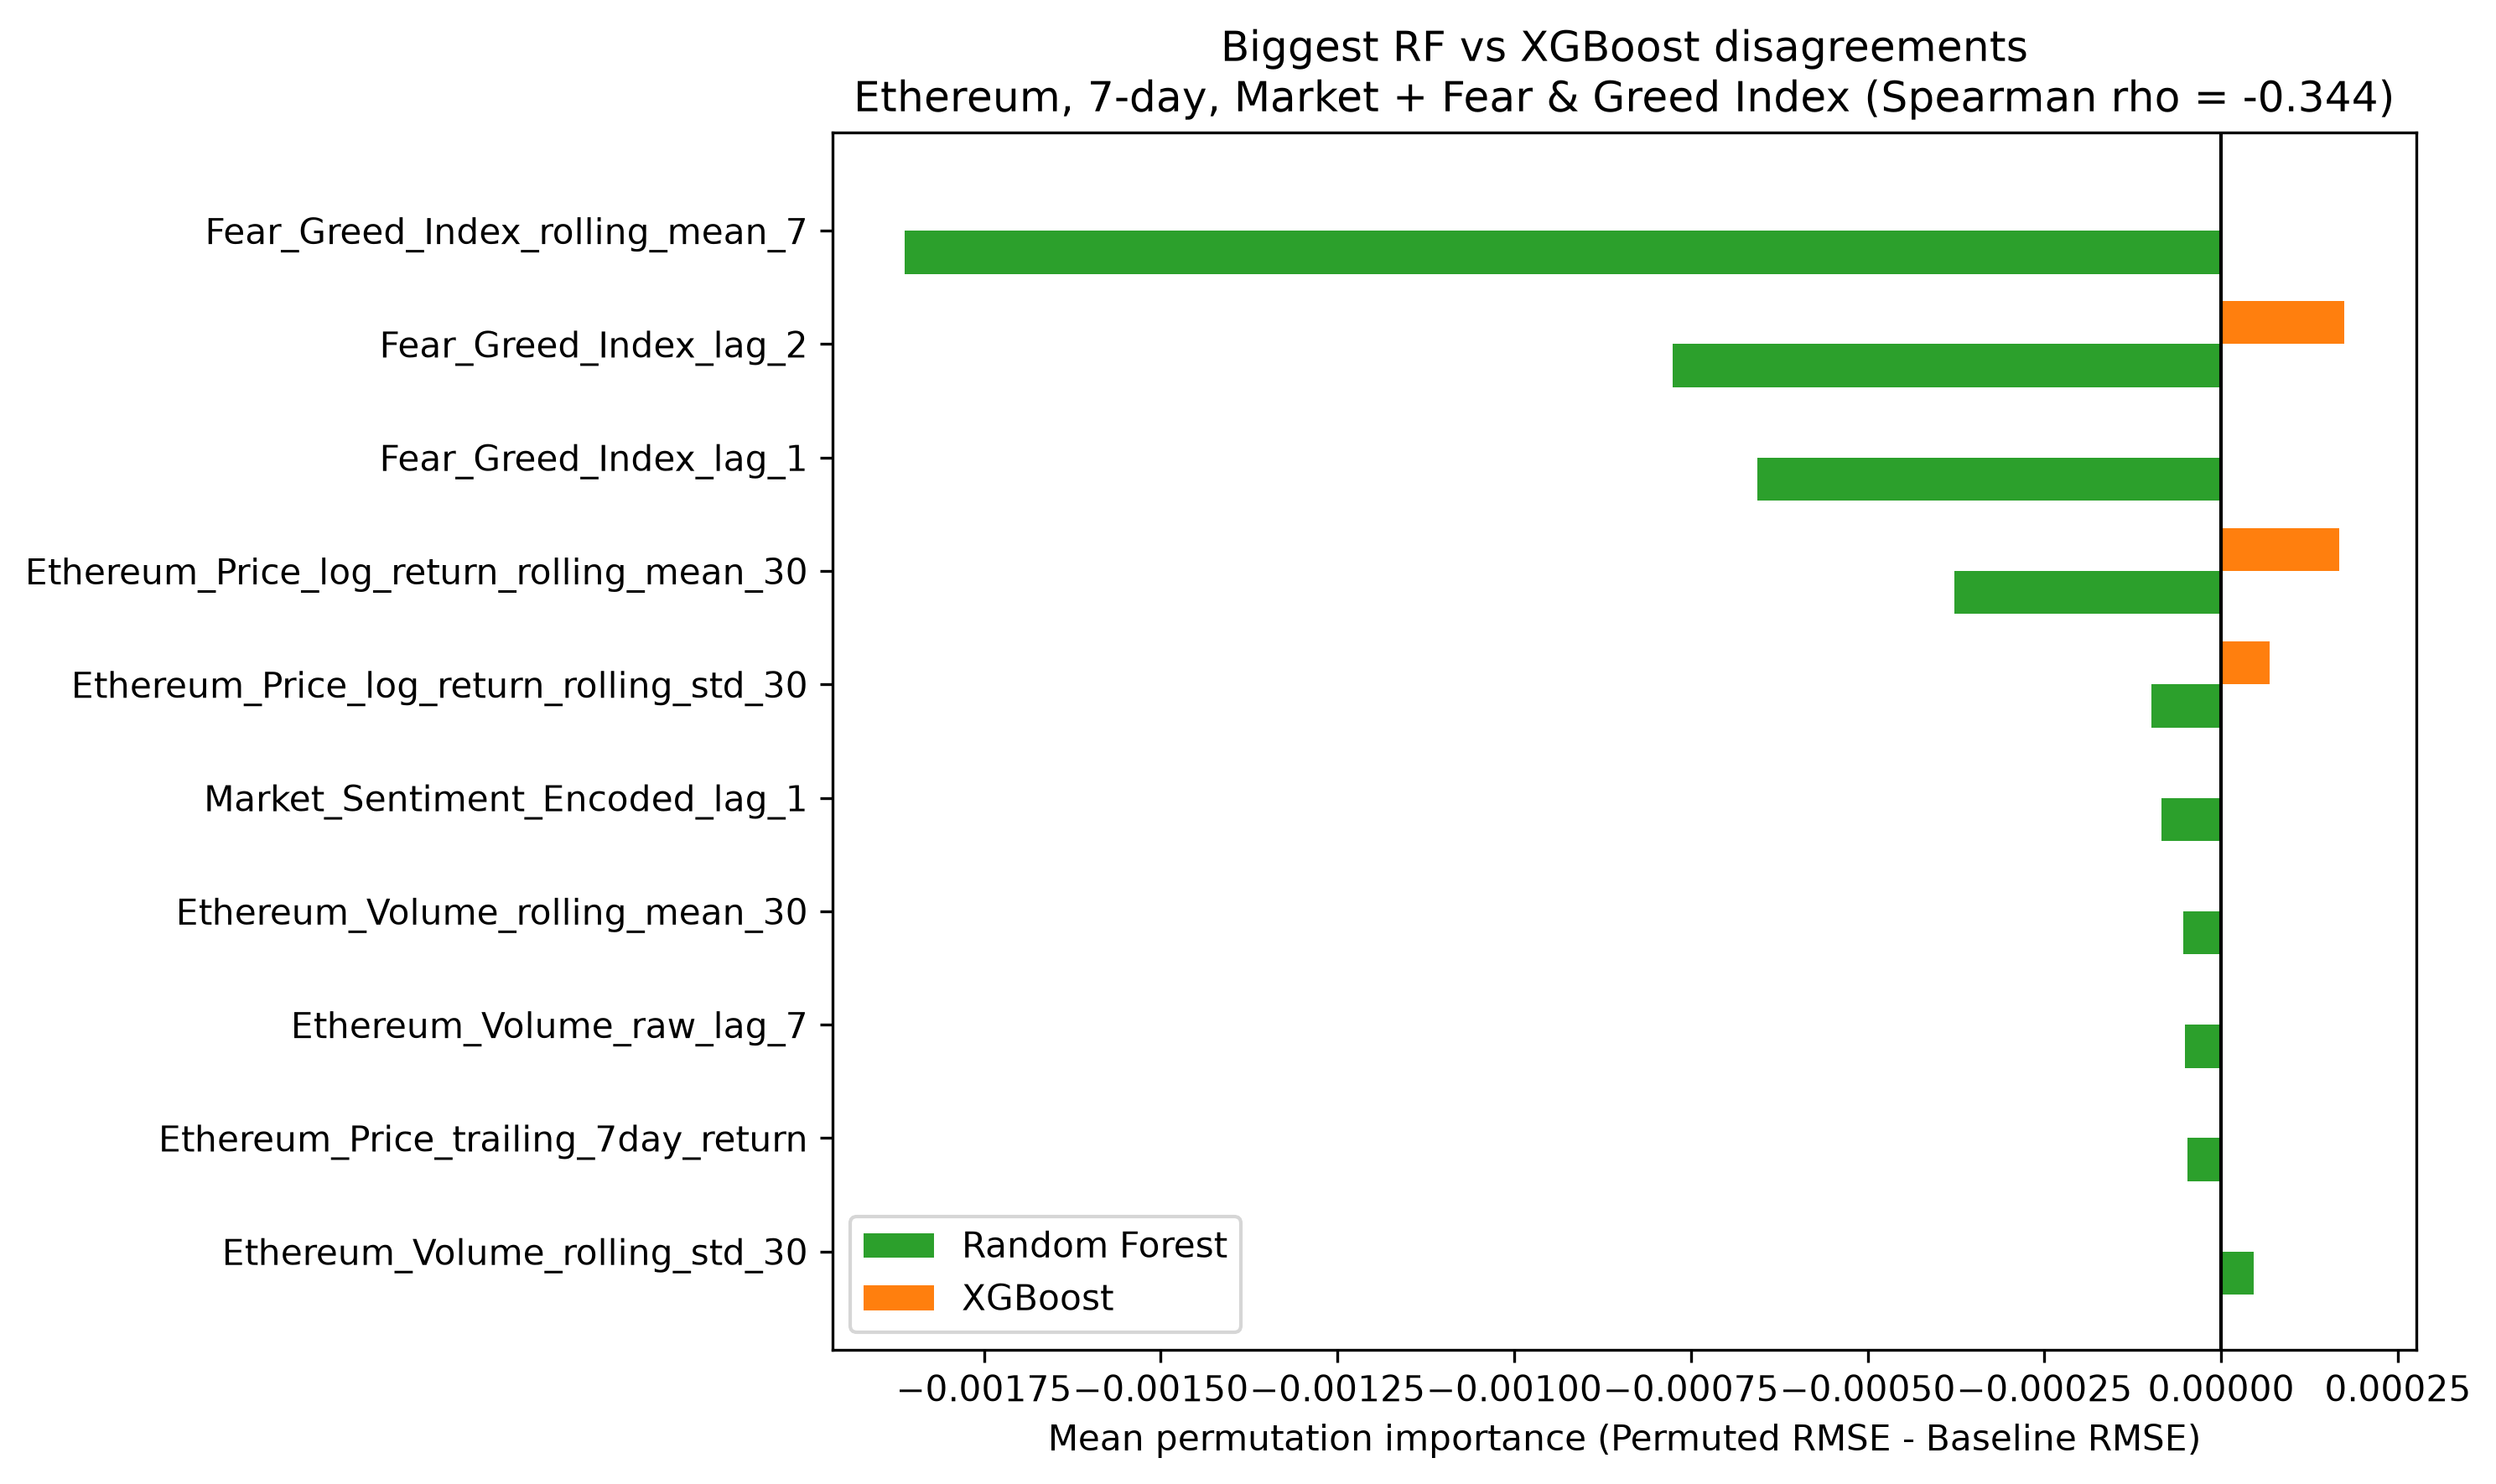

Saved: disagreement_detail_worst_agreement_configuration.png


In [8]:
valid = original_agreement.dropna(subset=["spearman_rho"])
worst = valid.loc[valid["spearman_rho"].idxmin()]
asset, horizon, fset = worst["asset"], worst["horizon"], worst["feature_set_key"]
rho = worst["spearman_rho"]
fset_display = DISPLAY_NAMES.get(fset, fset)

print(f"Lowest rank-agreement configuration: {asset}, {horizon}-day, {fset_display} -- Spearman rho = {rho:.3f}")

subset = original_cross_model[
    (original_cross_model["asset"] == asset) & (original_cross_model["horizon"] == horizon)
    & (original_cross_model["feature_set_key"] == fset) & (original_cross_model["both_available"])
].copy()

top_disagree = subset.sort_values("abs_difference", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(top_disagree))
height = 0.38
ax.barh(y + height / 2, top_disagree[RF_COL], height=height, label="Random Forest", color="#2ca02c")
ax.barh(y - height / 2, top_disagree[XGB_COL], height=height, label="XGBoost", color="#ff7f0e")
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(top_disagree["feature"]); ax.invert_yaxis()
ax.set_xlabel("Mean permutation importance (Permuted RMSE - Baseline RMSE)")
ax.set_title(f"Biggest RF vs XGBoost disagreements\n{asset}, {horizon}-day, {fset_display} (Spearman rho = {rho:.3f})")
ax.legend()
plt.tight_layout()
path_disagreement = FIGURES_DIR / "disagreement_detail_worst_agreement_configuration.png"
plt.savefig(path_disagreement, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path_disagreement)))
print(f"Saved: {path_disagreement.name}")


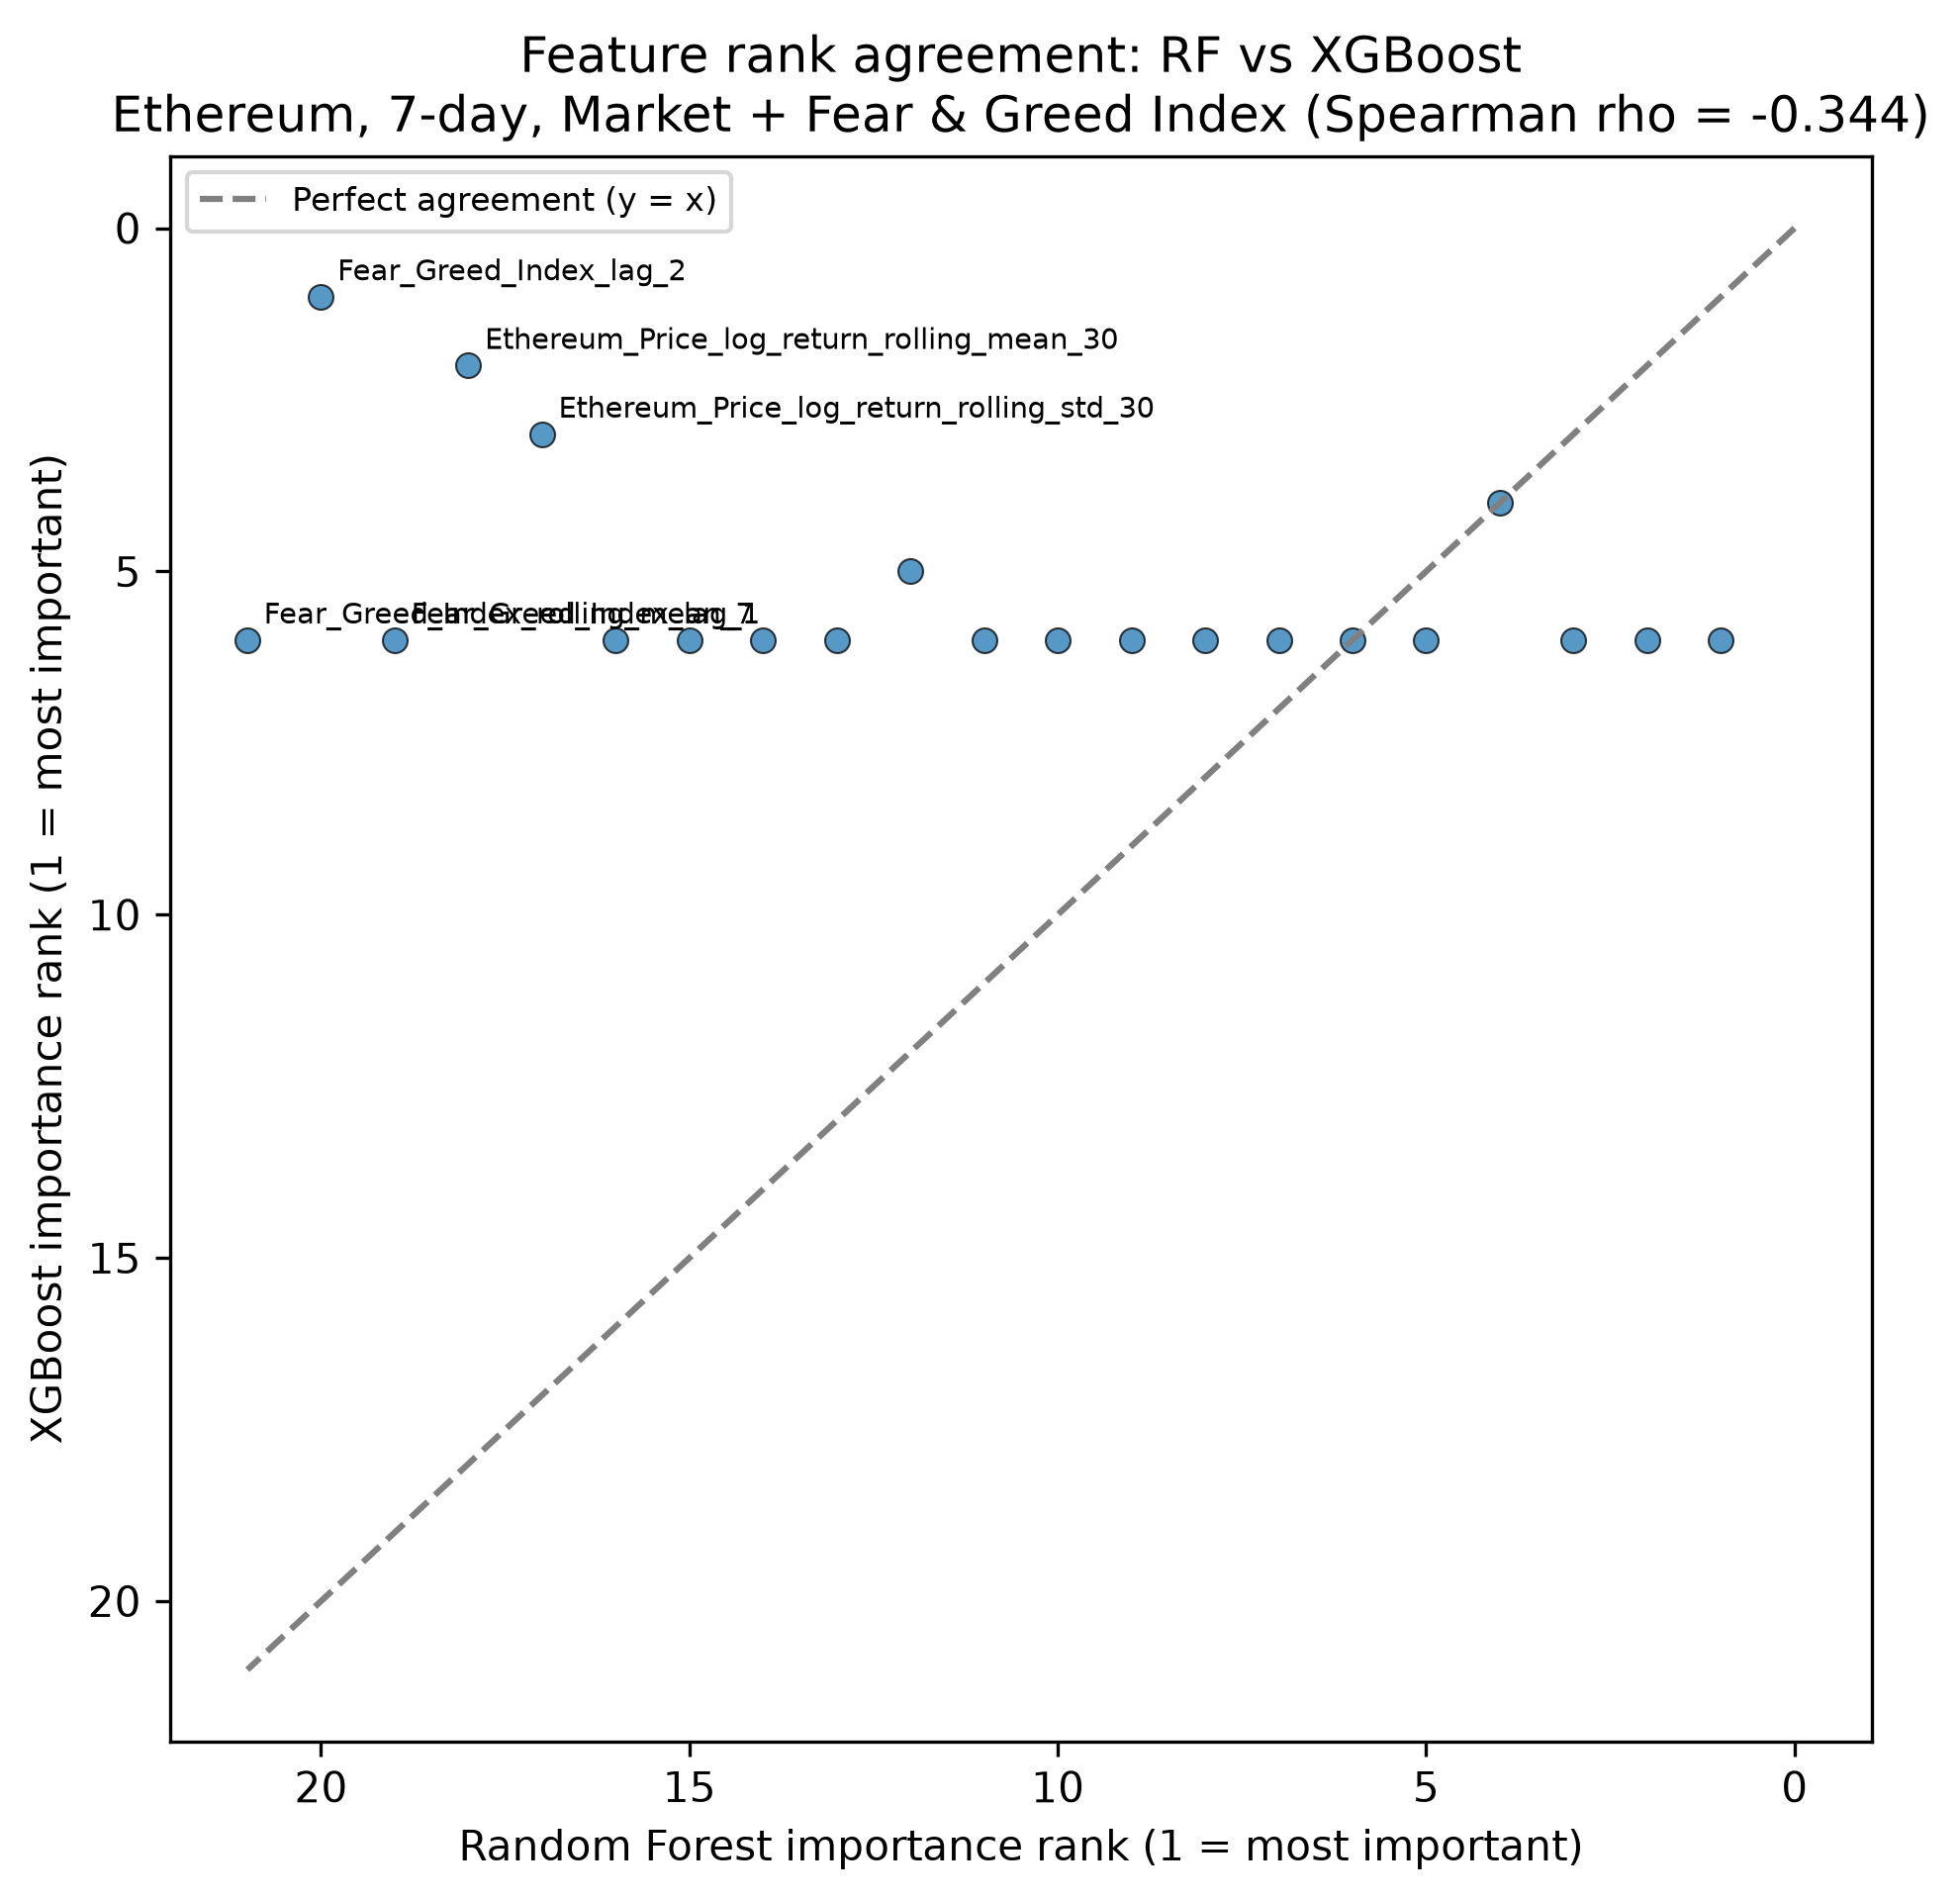

Saved: rank_scatter_worst_agreement_configuration.png


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(subset[RF_RANK_COL], subset[XGB_RANK_COL], alpha=0.75, edgecolor="black", linewidth=0.5)
max_rank = max(subset[RF_RANK_COL].max(), subset[XGB_RANK_COL].max())
ax.plot([0, max_rank], [0, max_rank], linestyle="--", color="gray", label="Perfect agreement (y = x)")
for _, row in subset.sort_values("abs_difference", ascending=False).head(5).iterrows():
    ax.annotate(row["feature"], (row[RF_RANK_COL], row[XGB_RANK_COL]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Random Forest importance rank (1 = most important)")
ax.set_ylabel("XGBoost importance rank (1 = most important)")
ax.set_title(f"Feature rank agreement: RF vs XGBoost\n{asset}, {horizon}-day, {fset_display} (Spearman rho = {rho:.3f})")
ax.legend(loc="upper left", fontsize=8)
ax.invert_yaxis(); ax.invert_xaxis()
plt.tight_layout()
path_rank_scatter = FIGURES_DIR / "rank_scatter_worst_agreement_configuration.png"
plt.savefig(path_rank_scatter, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path_rank_scatter)))
print(f"Saved: {path_rank_scatter.name}")


**Reading these two charts.** The labelled points and bars are the features Random Forest and XGBoost disagree on most -- one model ranks it near the top, the other doesn't. The scatter plot shows this in rank terms, the bar chart shows it in raw importance terms. Together they explain what's actually behind the 0.247 mean agreement number, rather than leaving it as just a number to take on faith.


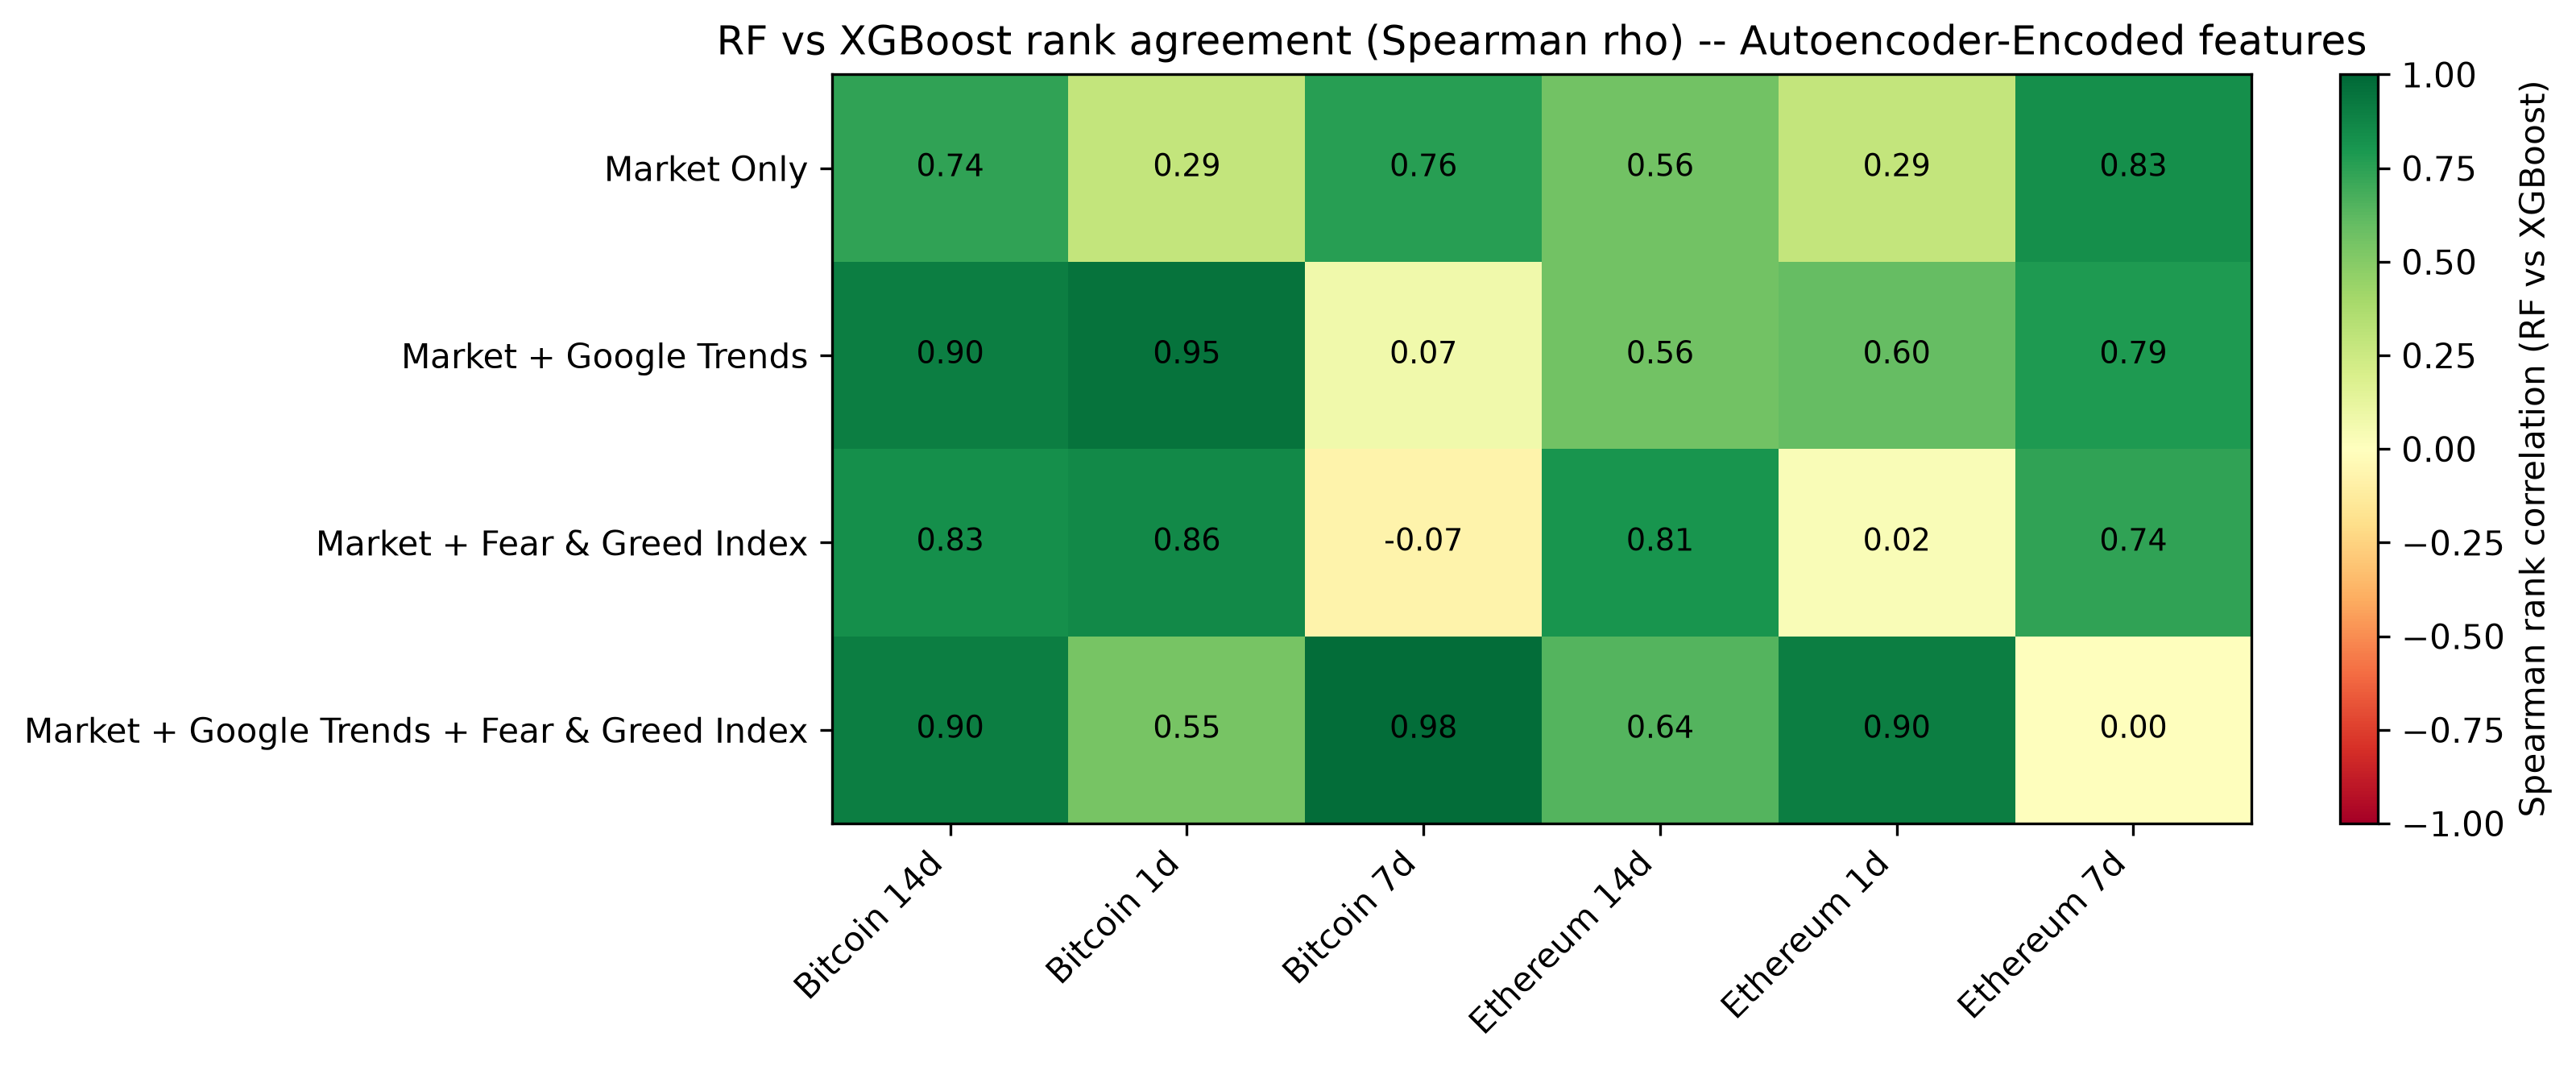

Saved: rank_agreement_heatmap_autoencoder.png


In [10]:
pivot_ae = build_heatmap_pivot(rank_agreement_ae)
plot_heatmap(
    pivot_ae,
    "RF vs XGBoost rank agreement (Spearman rho) -- Autoencoder-Encoded features",
    FIGURES_DIR / "rank_agreement_heatmap_autoencoder.png",
)


## 8. Summary

Everything from this notebook is saved under `results/feature_importance_autoencoder/` -- a new folder, nothing under `results/feature_importance/` was touched:

- `raw/permutation_importance_autoencoder_long.csv` -- the full 48-experiment autoencoder-encoded PFI grid.
- `processed/full_feature_dictionary.csv` -- every Original feature plus the 8 encoded dimensions in one table.
- `processed/cross_model_comparison_autoencoder.csv` and `rank_agreement_summary_autoencoder.csv` -- RF vs XGBoost agreement for the autoencoder-encoded branch.
- `processed/combined_importance_ranking.csv` -- both branches in one long table.
- `figures/` -- the rank-agreement heatmaps and the worst-agreement disagreement charts.

Don't assume the autoencoder-encoded branch's agreement number matches the Original branch's 0.247 -- an 8-dimensional latent space and a 14-25 dimensional engineered-feature space are different enough problems that there's no reason to expect the same result; just go with whatever it actually came out to above.

The tab issue in Section 6 is a deployment thing, not something fixed here -- check it against your actual Cloud Run setup using the two things listed there.
